# Feature Importance — v2-9 PINN (grid model, bounded physics)

Feature importance for the v2-9 model trained in `cotabato_grid_v2-9.ipynb`
(`MODEL_DIR` below, `fold-{N}-model-v3.keras`): physics-only head, cohesion bounded to
0–30 kPa, soft ac/PGA clamp, learnable Newmark threshold. Same method as
`feature_importance_v2_8.ipynb`, so the two can be compared directly:

1. **Permutation importance** — shuffle one feature (or feature group) and measure the
   **drop in AUC** on held-out labelled data. Model-agnostic, uses the real labels, and
   repeated over every fold so the ranking's stability is visible.
2. **SHAP** (KernelExplainer, one fold) — per-prediction attributions.

Inputs are prepared exactly as `run_model_v3.py` does for inference: `preprocessing()`
(slope ≥ 10°), soil indices, then the **fold's own transform manifest** (log1p / clip /
imputation flags). Skipping that replay would measure importance on inputs the model
never saw in training.

**Reading the v2-9 results.** The prediction is the Newmark chain alone, so every input
reaches it through one of three routes: the geotechnical MLP (cohesion, φ), the wetness
term (m) or the FOS / displacement formula itself (slope, PGA, bulk density, soil
thickness). `Prc_mean` is hidden from the MLP and recharge is a fixed constant, so it has
no route left and should score ≈ 0. `Slope_mean` is hidden from the MLP but still enters
the FOS directly, so its importance is purely physical.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from py_files.data import dataframe_to_dataset
from run_model_v3 import (
    SUSCEPTIBILITY_OUTPUT,
    build_model_inputs,
    find_transforms_manifest,
    load_and_preprocess,
    load_trained_model,
    replay_transforms,
)

## 1. Configuration

In [2]:
import os

# v2-9 bounded physics (cotabato_grid_v2-9.ipynb). v2-8 grid model = ".../grid/unconditioned",
# first v2-9 run = ".../grid/soil_conditioned_v2-9". FI_MODEL_DIR overrides it without
# editing, e.g. to run all three under identical settings.
MODEL_DIR = Path(os.environ.get(
    "FI_MODEL_DIR",
    PROJECT_ROOT / "outputs/obj2/wetness/v4-Fixed-Recharge/grid/dimensional-wetness/soil_conditioned_v2-9",
))
FOLDS = [1, 2, 3, 4, 5]

# Held-out data: Kidapawan was never in the Makilala training grid. Swap in
# `combined_mapped.gpkg` to see importance on the training distribution instead.
DATA_PATH = PROJECT_ROOT / "datasets/nc_mapped.gpkg"
PGA_COL = "PGA2_max"

# Keep only the area the landslide inventory surveyed. Outside the LSI raster's
# extent `landslide = 0` means "never mapped", not "no landslide", and those fake
# negatives turn importance into "which feature tells Makilala from elsewhere".
CLIP_TO_LSI = True
LSI_PATH = Path("~/Downloads/LSI_NorthCotabato_10m (1).tif").expanduser()

# Drop cells overlapping the training grid so the evaluation is held out. The
# training grid (combined_mapped.gpkg) holds cells whose CENTRE lies in this ROI;
# any cell touching one of them has its centre within one cell diagonal of it.
EXCLUDE_TRAINING = True
TRAINING_ROI_PATH = PROJECT_ROOT / "datasets/roi/makilala_boundary.gpkg"
GRID_CELL_M = 25.0

N_REPEATS = 3            # shuffles per feature per fold
PRED_BATCH = 4096        # inference batch size (larger = faster, more memory)
SEED = 42

SHAP_FOLD = 1
SHAP_N_BACKGROUND = 100
SHAP_N_EXPLAIN = 300     # KernelExplainer cost grows with this; ~10-20 min at 300

FIG_DIR = PROJECT_ROOT / "outputs/figures/feature_importance" / MODEL_DIR.name
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Inputs derived from the same source are shuffled together, otherwise the model
# still sees the information through the un-shuffled partner and the importance
# of both is understated.
FEATURE_GROUPS = {
    "Soil type map (type + soil_type_idx)": ["type", "soil_type_idx"],
    "Imputation flags (*_was_imputed)": [
        "BUK_mean_was_imputed", "SoilThc_mean_was_imputed", "PGA2_max_was_imputed",
        "Clay_mean_was_imputed", "Silt_mean_was_imputed", "Sand_mean_was_imputed",
    ],
}

## 2. Load and prepare data

In [3]:
import geopandas as gpd
import rasterio
from shapely.geometry import box

lsi_extent = None
if CLIP_TO_LSI:
    with rasterio.open(LSI_PATH) as lsi:
        lsi_extent = tuple(lsi.bounds)

# The bbox read pulls only the inventory's area from the GeoPackage spatial index;
# the exact centre-in-extent test below trims the cells straddling its edge.
df, feature_cols, _df_full = load_and_preprocess(str(DATA_PATH), bbox=lsi_extent)
centres = df.geometry.centroid
print(f"{len(df):,} rows loaded (slope >= 10, no missing inputs)")

if CLIP_TO_LSI:
    inside_lsi = centres.within(box(*lsi_extent))
    print(f"Clip to LSI extent: dropping {int((~inside_lsi).sum()):,} rows outside it")
    df, centres = df[inside_lsi], centres[inside_lsi]

if EXCLUDE_TRAINING:
    roi = gpd.read_file(TRAINING_ROI_PATH).to_crs(df.crs)
    training_zone = roi.union_all().buffer(GRID_CELL_M * np.sqrt(2))
    in_training = centres.within(training_zone)
    print(f"Exclude training area: dropping {int(in_training.sum()):,} rows "
          f"({int(df.loc[in_training, 'landslide'].sum()):,} landslides) near {TRAINING_ROI_PATH.name}")
    df = df[~in_training]

# The FOS divides by bulk density, so BUK_mean <= 0 (soil-raster nodata written as 0)
# yields NaN susceptibility. Drop those rows up front: filtering predictions alone is
# not enough, since shuffling BUK_mean would carry the zeros into other rows.
invalid_physics = df["BUK_mean"] <= 0
if invalid_physics.any():
    print(f"Dropping {int(invalid_physics.sum()):,} rows with BUK_mean <= 0 "
          f"({int(df.loc[invalid_physics, 'landslide'].sum())} landslides) — physics undefined")
    df = df[~invalid_physics]

y = df["landslide"].astype(int).to_numpy()
print(f"{len(df):,} rows after preprocessing (slope >= 10), {y.sum():,} landslides ({y.mean():.2%})")

703,384 rows loaded (slope >= 10, no missing inputs)
Clip to LSI extent: dropping 1,026 rows outside it
Exclude training area: dropping 287,952 rows (14,500 landslides) near makilala_boundary.gpkg
414,406 rows after preprocessing (slope >= 10), 5,975 landslides (1.44%)


In [4]:
def model_path(fold):
    return MODEL_DIR / f"fold-{fold}-model-v3.keras"


def prepare_inputs(model, fold):
    """Model-ready frame for one fold: its own transform manifest, then input selection."""
    manifest = find_transforms_manifest(str(model_path(fold)))
    model_df = replay_transforms(df, model, manifest)
    return build_model_inputs(model_df, model, pga_col=PGA_COL)


def predict(model, feed):
    """Susceptibility (final head) for a model-input frame."""
    ds = dataframe_to_dataset(feed.copy(), shuffle=False, batch_size=PRED_BATCH)
    preds = model.predict(ds, verbose=0)
    if isinstance(preds, dict):
        preds = preds[SUSCEPTIBILITY_OUTPUT]
    preds = np.asarray(preds).flatten()
    n_bad = int((~np.isfinite(preds)).sum())
    if n_bad:
        raise ValueError(
            f"{n_bad:,} non-finite predictions. Check the physics inputs of those rows "
            "for zeros / nodata (BUK_mean, SoilThc_mean, PGA2_max) and filter them in section 2."
        )
    return preds


def importance_units(input_names):
    """Each group as one unit, every other model input on its own."""
    grouped = {c for cols in FEATURE_GROUPS.values() for c in cols}
    units = {name: [c for c in cols if c in input_names] for name, cols in FEATURE_GROUPS.items()}
    units = {name: cols for name, cols in units.items() if cols}
    units.update({c: [c] for c in input_names if c not in grouped})
    return units

## 3. Permutation importance (all folds)

`importance = baseline AUC − AUC with the unit shuffled`. Positive = the model relies on it;
≈ 0 = unused (or redundant with another input); negative = noise. A unit that is
**constant** in this data (e.g. imputation flags when nothing was imputed) cannot be
measured by shuffling and is reported as NaN rather than a misleading 0.

In [5]:
rng = np.random.default_rng(SEED)
rows, baselines = [], {}

for fold in FOLDS:
    model = load_trained_model(str(model_path(fold)))
    feed = prepare_inputs(model, fold)
    inputs = [t.name for t in model.inputs]
    base_auc = roc_auc_score(y, predict(model, feed))
    baselines[fold] = base_auc
    print(f"fold {fold}: baseline AUC {base_auc:.4f}")

    for unit, cols in importance_units(inputs).items():
        if all(feed[c].nunique() <= 1 for c in cols):
            rows.append({"fold": fold, "unit": unit, "repeat": 0, "auc_drop": np.nan})
            continue
        for repeat in range(N_REPEATS):
            # One permutation for the whole group keeps its members consistent per row.
            order = rng.permutation(len(feed))
            shuffled = feed.copy()
            for c in cols:
                shuffled[c] = feed[c].to_numpy()[order]
            auc = roc_auc_score(y, predict(model, shuffled))
            rows.append({"fold": fold, "unit": unit, "repeat": repeat, "auc_drop": base_auc - auc})

perm = pd.DataFrame(rows)
print(f"\nBaseline AUC across folds: {np.mean(list(baselines.values())):.4f} "
      f"± {np.std(list(baselines.values())):.4f}")

  Replaying transforms from /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/dimensional-wetness/soil_conditioned_v2-9/v1_cotabato_transforms_fold1.json (v1_cotabato_fold1): log1p ['Elev_mean', 'BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed'], clip ['Elev_mean']
  PGA input 'PGA2_max' <- data 'PGA2_max'. Medians in data: PGA2_max=0.2633, PGA2_max_was_imputed=0.0000
  Categorical 'type': 98.7% of values in the model vocabulary ['Sandy Clay Loam', 'Undifferentiated', '[UNK]']
fold 1: baseline AUC 0.5727
  Replaying transforms from /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/dimensional-wetness/soil_conditioned_v2-9/v1_cotabato_transforms_fold2.json (v1_cotabato_fold2): log1p ['Elev_mean', 'BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imp

In [6]:
perm_summary = (
    perm.groupby("unit")["auc_drop"]
    .agg(mean="mean", std="std", min="min", max="max")
    .sort_values("mean", ascending=False)
)
# Rank within each fold, then how much the rank moves across folds.
fold_means = perm.groupby(["fold", "unit"])["auc_drop"].mean().unstack()
perm_summary["rank_spread"] = (
    fold_means.rank(axis=1, ascending=False).max() - fold_means.rank(axis=1, ascending=False).min()
)
perm_summary.to_csv(FIG_DIR / "permutation_importance.csv")
perm_summary.round(4)

,mean,std,min,max,rank_spread
unit,,,,,
Slope_mean,0.0668,0.0072,0.0535,0.0772,0.0
ContributingFactor_mean,0.0133,0.0033,0.0084,0.0200,0.0
Soil type map (type + soil_type_idx),0.0038,0.0074,-0.0039,0.0175,5.0
BUK_mean,0.0038,0.0005,0.0031,0.0046,1.0
PGA2_max,0.0036,0.0010,0.0024,0.0061,2.0
Prc_mean,0.0009,0.0005,0.0002,0.0018,1.0
Elev_mean,0.0000,0.0000,0.0000,0.0000,1.0
soil_texture_idx,-0.0066,0.0013,-0.0090,-0.0046,1.0
SoilThc_mean,-0.0068,0.0045,-0.0115,0.0003,2.0


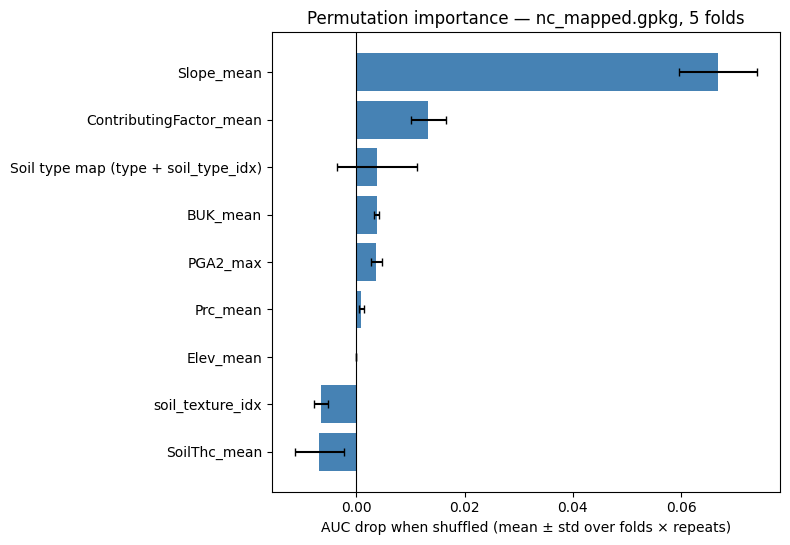

Constant in this data, not measurable by shuffling: ['Imputation flags (*_was_imputed)']


In [7]:
plot_df = perm_summary.dropna(subset=["mean"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 0.45 * len(plot_df) + 1.5))
ax.barh(plot_df.index, plot_df["mean"], xerr=plot_df["std"], color="steelblue", capsize=3)
ax.axvline(0, color="k", linewidth=0.8)
ax.set_xlabel("AUC drop when shuffled (mean ± std over folds × repeats)")
ax.set_title(f"Permutation importance — {DATA_PATH.name}, {len(FOLDS)} folds")
fig.tight_layout()
fig.savefig(FIG_DIR / "permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

unmeasured = perm_summary.index[perm_summary["mean"].isna()].tolist()
if unmeasured:
    print(f"Constant in this data, not measurable by shuffling: {unmeasured}")

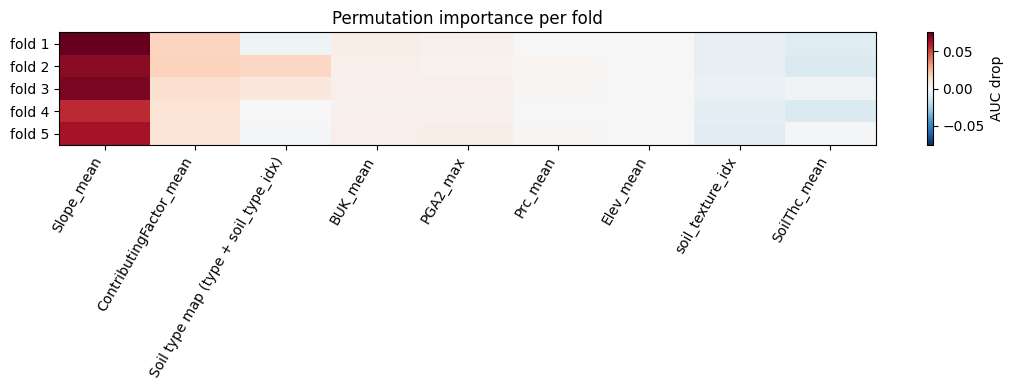

In [8]:
# Per-fold heatmap: a feature that matters in one fold only is not a robust finding.
heat = fold_means[perm_summary.dropna(subset=["mean"]).index]
fig, ax = plt.subplots(figsize=(1.0 * len(heat.columns) + 2, 0.5 * len(FOLDS) + 1.5))
im = ax.imshow(heat.to_numpy(), cmap="RdBu_r", aspect="auto",
               vmin=-np.nanmax(np.abs(heat.to_numpy())), vmax=np.nanmax(np.abs(heat.to_numpy())))
ax.set_xticks(range(len(heat.columns)), heat.columns, rotation=60, ha="right")
ax.set_yticks(range(len(heat.index)), [f"fold {f}" for f in heat.index])
fig.colorbar(im, ax=ax, label="AUC drop")
ax.set_title("Permutation importance per fold")
fig.tight_layout()
fig.savefig(FIG_DIR / "permutation_importance_per_fold.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. SHAP (one fold)

KernelExplainer on the fold-`SHAP_FOLD` model, `type` one-hot expanded and aggregated back
to one column (`py_files.metrics`, same as the v2_8 notebook). SHAP explains the
**prediction**, not accuracy: a feature can move predictions a lot (high SHAP) yet add
little AUC (low permutation importance) if it pushes positives and negatives alike.

In [9]:
import shap
from py_files.metrics import aggregate_categorical_shap, compute_shap_values

shap_model = load_trained_model(str(model_path(SHAP_FOLD)))
shap_feed = prepare_inputs(shap_model, SHAP_FOLD).drop(columns=["landslide"])
shap_inputs = [t.name for t in shap_model.inputs]
shap_categorical = [t.name for t in shap_model.inputs if t.dtype == "string"]

shap_values_exp, shap_data_exp, shap_names_exp = compute_shap_values(
    shap_model, shap_feed, shap_inputs,
    categorical_cols=shap_categorical,
    n_background=SHAP_N_BACKGROUND, n_explain=SHAP_N_EXPLAIN,
)
shap_values, shap_data, shap_names = aggregate_categorical_shap(
    shap_values_exp, shap_data_exp, shap_names_exp, categorical_cols=shap_categorical,
)
print(f"SHAP values: {shap_values.shape}")

/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  Replaying transforms from /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/dimensional-wetness/soil_conditioned_v2-9/v1_cotabato_transforms_fold1.json (v1_cotabato_fold1): log1p ['Elev_mean', 'BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed'], clip ['Elev_mean']
  PGA input 'PGA2_max' <- data 'PGA2_max'. Medians in data: PGA2_max=0.2633, PGA2_max_was_imputed=0.0000
  Categorical 'type': 98.7% of values in the model vocabulary ['Sandy Clay Loam', 'Undifferentiated', '[UNK]']


  0%|          | 0/300 [00:00<?, ?it/s]/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/shap/explainers/_kernel.py:706: RuntimeWarning: divide by zero encountered in matmul
  w = np.linalg.solve(X.T @ WX, WX.T @ y)
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/shap/explainers/_kernel.py:706: RuntimeWarning: overflow encountered in matmul
  w = np.linalg.solve(X.T @ WX, WX.T @ y)
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/shap/explainers/_kernel.py:706: RuntimeWarning: invalid value encountered in matmul
  w = np.linalg.solve(X.T @ WX, WX.T @ y)
100%|██████████| 300/300 [03:34<00:00,  1.40it/s]

SHAP values: (300, 16)


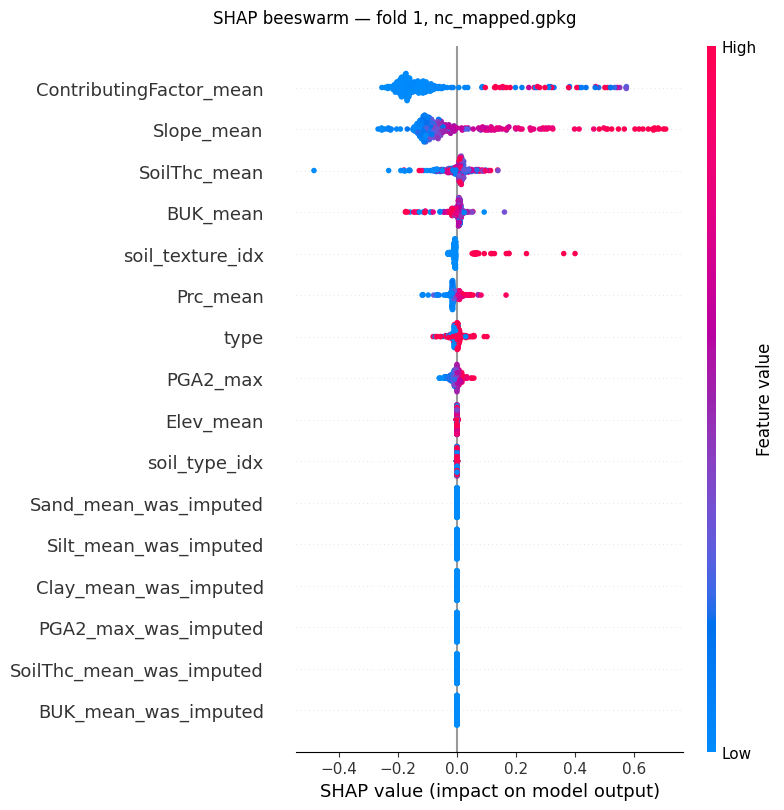

In [10]:
shap.summary_plot(shap_values, shap_data, feature_names=shap_names, show=False)
plt.gcf().suptitle(f"SHAP beeswarm — fold {SHAP_FOLD}, {DATA_PATH.name}", y=1.02)
plt.savefig(FIG_DIR / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

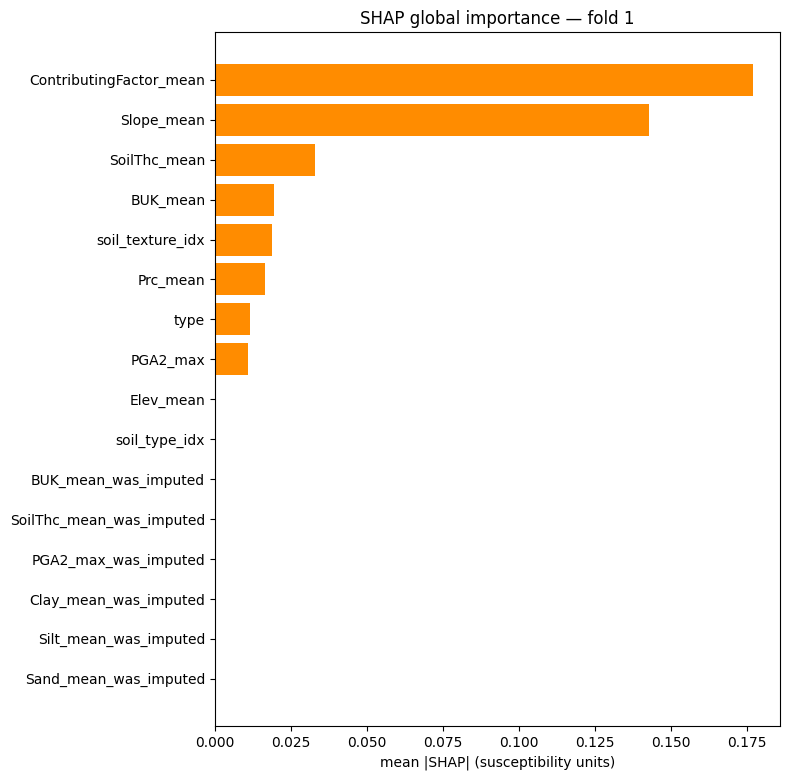

,feature,mean_abs_shap
0,ContributingFactor_mean,0.1769
1,Slope_mean,0.1427
2,SoilThc_mean,0.0327
3,BUK_mean,0.0193
4,soil_texture_idx,0.0189
5,Prc_mean,0.0163
6,type,0.0114
7,PGA2_max,0.0110
8,Elev_mean,0.0002
9,soil_type_idx,0.0002


In [11]:
shap_importance = (
    pd.DataFrame({"feature": shap_names, "mean_abs_shap": np.abs(shap_values).mean(axis=0)})
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)
shap_importance.to_csv(FIG_DIR / "shap_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 0.4 * len(shap_importance) + 1.5))
plot_s = shap_importance.iloc[::-1]
ax.barh(plot_s["feature"], plot_s["mean_abs_shap"], color="darkorange")
ax.set_xlabel("mean |SHAP| (susceptibility units)")
ax.set_title(f"SHAP global importance — fold {SHAP_FOLD}")
fig.tight_layout()
fig.savefig(FIG_DIR / "shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()
shap_importance.round(4)

## 5. Permutation vs SHAP ranking

In [12]:
# SHAP is per input; fold groups back into the permutation units so the ranks line up.
unit_of = {c: unit for unit, cols in importance_units(shap_inputs).items() for c in cols}
shap_by_unit = (
    shap_importance.assign(unit=shap_importance["feature"].map(unit_of))
    .groupby("unit")["mean_abs_shap"].sum()
)
comparison = pd.DataFrame({
    "perm_auc_drop": perm_summary["mean"],
    "mean_abs_shap": shap_by_unit,
})
comparison["perm_rank"] = comparison["perm_auc_drop"].rank(ascending=False)
comparison["shap_rank"] = comparison["mean_abs_shap"].rank(ascending=False)
comparison = comparison.sort_values("perm_rank")
comparison.to_csv(FIG_DIR / "importance_comparison.csv")
print(f"Figures and CSVs in {FIG_DIR}")
comparison.round(4)

Figures and CSVs in /Users/giogonzales/Documents/ml-prep/mlprep/outputs/figures/feature_importance/soil_conditioned_v2-9


,perm_auc_drop,mean_abs_shap,perm_rank,shap_rank
unit,,,,
Slope_mean,0.0668,0.1427,1.0,2.0
ContributingFactor_mean,0.0133,0.1769,2.0,1.0
Soil type map (type + soil_type_idx),0.0038,0.0116,3.0,7.0
BUK_mean,0.0038,0.0193,4.0,4.0
PGA2_max,0.0036,0.0110,5.0,8.0
Prc_mean,0.0009,0.0163,6.0,6.0
Elev_mean,0.0000,0.0002,7.0,9.0
soil_texture_idx,-0.0066,0.0189,8.0,5.0
SoilThc_mean,-0.0068,0.0327,9.0,3.0
